## Proposed Dual-Graph AC-SMFAE

### Data Ingestion, Preprocessing and Validation
Dataset: Colon Cancer

In [4]:

import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Load the Colon dataset
file_path = "../data/preprocessed/Colon.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"Dataset not found: {file_path}\n"
        f"Current working directory: {os.getcwd()}"
    )

df = pd.read_csv(file_path)

# 2. Separate gene features and ground-truth labels
X_raw = df.iloc[:, :-1].to_numpy(dtype=np.float64)
y = df.iloc[:, -1].to_numpy()

# 3. Validate the dataset structure
if X_raw.shape != (62, 2000):
    print(f"Warning: Expected feature shape (62, 2000), got {X_raw.shape}")

if pd.isna(y).any():
    raise ValueError("Missing values found in the label column.")

if not np.isfinite(X_raw).all():
    raise ValueError(
        "Feature data contains missing or infinite values. "
        "Handle them before standardization."
    )

# 4. Z-score standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 5. Transpose to paper notation: genes x samples
X = X_scaled.T

# 6. Dataset summary and validation
print("CELL 1: COLON DATASET — DATA INGESTION & SETUP")
print("Proposed Dual-Graph AC-SMFAE")

print(f"Dataset path              : {os.path.abspath(file_path)}")
print(f"Original DataFrame shape  : {df.shape}")
print(f"Raw feature matrix shape  : {X_raw.shape}")
print(f"Standardized matrix shape : {X.shape} (genes × samples)")
print(f"Labels vector shape       : {y.shape}")
print(f"Number of samples         : {X.shape[1]}")
print(f"Number of gene features   : {X.shape[0]}")
print(f"Number of classes         : {len(np.unique(y))}")
print(f"Class labels              : {np.unique(y)}")
print(f"Missing values in X       : {np.isnan(X).sum()}")
print(f"Non-finite values in X    : {(~np.isfinite(X)).sum()}")


assert X.shape == (2000, 62), (
    f"Expected X shape (2000, 62), got {X.shape}"
)
assert len(np.unique(y)) == 2, "Expected exactly 2 classes."
assert np.isfinite(X).all(), "X contains non-finite values."

print("Dataset validation passed successfully.")

CELL 1: COLON DATASET — DATA INGESTION & SETUP
Proposed Dual-Graph AC-SMFAE
Dataset path              : d:\Projects\SMFS-AutoEncoder\data\preprocessed\Colon.csv
Original DataFrame shape  : (62, 2001)
Raw feature matrix shape  : (62, 2000)
Standardized matrix shape : (2000, 62) (genes × samples)
Labels vector shape       : (62,)
Number of samples         : 62
Number of gene features   : 2000
Number of classes         : 2
Class labels              : [-1  1]
Missing values in X       : 0
Non-finite values in X    : 0
Dataset validation passed successfully.


Data Ingestion and Setup for the Colon Cancer dataset is complete. The dataset contains **2,000 gene features and 62 samples**, with two label classes (\(-1\) and \(1\)). Z-score standardization has been applied successfully. The **Dual-Graph AC-SMFAE (Combination C)** architecture will now be implemented and evaluated on the Colon Cancer dataset.

### Model Training, Feature Selection & Evaluation

In [5]:
import numpy as np
from scipy import sparse
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, pairwise_distances
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Sigmoid activation
# ------------------------------------------------------------

def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-np.clip(u, -15.0, 15.0)))


# ------------------------------------------------------------
# 2. Hungarian matching accuracy
# ------------------------------------------------------------

def accuracy_score_hungarian(y_true, y_pred):
    _, y_true_enc = np.unique(y_true, return_inverse=True)
    _, y_pred_enc = np.unique(y_pred, return_inverse=True)

    n_true = len(np.unique(y_true_enc))
    n_pred = len(np.unique(y_pred_enc))

    contingency = np.zeros((n_pred, n_true), dtype=np.int64)

    for i in range(len(y_true_enc)):
        contingency[y_pred_enc[i], y_true_enc[i]] += 1

    row_ind, col_ind = linear_sum_assignment(
        contingency.max() - contingency
    )

    return contingency[row_ind, col_ind].sum() / len(y_true)


# ------------------------------------------------------------
# 3. Adaptive sample graph
# Input: genes x samples or latent_features x samples
# Output: similarity matrix S, degree matrix D, Laplacian L
# ------------------------------------------------------------

def construct_adaptive_graph(Z_or_X, k=5):
    distances = pairwise_distances(
        Z_or_X.T, metric="euclidean"
    )

    n_samples = Z_or_X.shape[1]
    S = np.zeros((n_samples, n_samples), dtype=np.float64)

    sigma = np.mean(distances) + 1e-8

    for i in range(n_samples):
        neighbours = np.argsort(distances[i])[1:k + 1]

        for j in neighbours:
            sim = np.exp(
                -(distances[i, j] ** 2) / (2.0 * sigma ** 2)
            )
            S[i, j] = sim
            S[j, i] = sim

    D = np.diag(S.sum(axis=1))
    L = D - S

    return S, D, L


# ------------------------------------------------------------
# 4. Sparse feature graph using cosine distance
# Input: genes x samples
# ------------------------------------------------------------

def construct_feature_graph_colon(X, k=5):
    distances = pairwise_distances(X, metric="cosine")
    n_features = X.shape[0]

    rows, cols, values = [], [], []
    sigma = np.mean(distances) + 1e-8

    for i in range(n_features):
        neighbours = np.argsort(distances[i])[1:k + 1]

        for j in neighbours:
            sim = np.exp(
                -(distances[i, j] ** 2) / (2.0 * sigma ** 2)
            )
            rows.append(i)
            cols.append(j)
            values.append(sim)

    S_F = sparse.csr_matrix(
        (values, (rows, cols)),
        shape=(n_features, n_features)
    )

    S_F = S_F.maximum(S_F.T)
    S_F.setdiag(0)
    S_F.eliminate_zeros()

    degree = np.asarray(S_F.sum(axis=1)).ravel()
    L_F = sparse.diags(degree) - S_F

    return L_F


# ------------------------------------------------------------
# 5. Dual-Graph AC-SMFAE training
# ------------------------------------------------------------

def train_dual_graph_ac_smfae_colon(
    X,
    k=5,
    m=200,
    alpha=1e-2,
    beta=1e-4,
    gamma=1e-3,
    omega=0.01,
    lam=1e-4,
    eta=1e-2,
    lr=5e-4,
    epochs=500,
    update_graph_every=20
):
    d, n = X.shape

    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    L_F = construct_feature_graph_colon(X, k=k)

    loss_history = []

    print("=== Dual-Graph AC-SMFAE: Colon Dataset ===")
    print(
        f"Genes={d}, Samples={n}, Latent={m}, "
        f"Alpha={alpha}, Eta={eta}, Lambda={lam}"
    )
    print(f"Sample graph shape : {L_S.shape}")
    print(f"Feature graph shape: {L_F.shape}")

    for epoch in range(1, epochs + 1):

        # Forward pass
        U = W1 @ X
        Z = sigmoid(U)
        X_hat = W2 @ Z

        # Update adaptive sample graph
        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)

        # Reconstruction loss
        recon_err = X - X_hat
        loss_recon = 0.5 / n * np.sum(recon_err ** 2)

        # Column-wise L2,1 sparsity
        w1_col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(w1_col_norms)

        # Weight decay
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)

        # Sample manifold loss
        loss_sample_manifold = (
            0.5 / n * gamma * np.trace(Z @ L_S @ Z.T)
        )

        # Feature manifold loss
        W1_LF = W1 @ L_F
        loss_feature_manifold = (
            0.5 / n * eta * np.sum(W1_LF * W1)
        )

        # Output manifold loss
        output_diff = H.T @ H - L_S
        loss_output_manifold = (
            0.5 / n * omega * np.sum(output_diff ** 2)
        )

        # Contractive penalty
        d_sig = Z * (1.0 - Z)
        h_prime_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq_rows = np.sum(W1 ** 2, axis=1)

        loss_contractive = (
            lam * np.sum(h_prime_sum * w1_sq_rows)
        )

        total_loss = (
            loss_recon
            + loss_sparse
            + loss_weight_decay
            + loss_sample_manifold
            + loss_feature_manifold
            + loss_output_manifold
            + loss_contractive
        )

        loss_history.append(float(total_loss))

        # Gradients
        grad_W2 = (
            -(recon_err @ Z.T) / n + beta * W2
        )

        dL_dZ = (
            -(W2.T @ recon_err) / n
            + gamma * (Z @ L_S) / n
        )

        dL_dU = dL_dZ * d_sig
        grad_W1_base = dL_dU @ X.T

        grad_W1_sparse = alpha * (
            W1 / w1_col_norms[None, :]
        )

        grad_W1_feature = eta * (W1 @ L_F) / n

        A_mat = 2.0 * (d_sig ** 2) * (1.0 - 2.0 * Z)

        grad_cae_1 = 2.0 * (
            h_prime_sum[:, None] * W1
        )

        grad_cae_2 = (
            w1_sq_rows[:, None] * (A_mat @ X.T)
        )

        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = (
            grad_W1_base
            + grad_W1_sparse
            + grad_W1_feature
            + grad_W1_cae
        )

        grad_W1 = np.clip(grad_W1, -5.0, 5.0)
        grad_W2 = np.clip(grad_W2, -5.0, 5.0)

        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        # Non-negative H update
        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8

        H = H * np.sqrt(
            np.maximum(num_H / den_H, 1e-8)
        )

        if epoch % 100 == 0 or epoch == 1:
            print(
                f"Epoch [{epoch:3d}/{epochs}] | "
                f"Total: {total_loss:10.4f} | "
                f"Recon: {loss_recon:10.4f} | "
                f"Feature Graph: {loss_feature_manifold:8.4f}"
            )

        if not (
            np.isfinite(W1).all()
            and np.isfinite(W2).all()
            and np.isfinite(H).all()
            and np.isfinite(total_loss)
        ):
            raise FloatingPointError(
                f"Non-finite value encountered at epoch {epoch}."
            )

    return W1, W2, H, loss_history


# ------------------------------------------------------------
# 6. Train model
# ------------------------------------------------------------

W1_colon, W2_colon, H_colon, loss_hist_colon = (
    train_dual_graph_ac_smfae_colon(
        X,
        k=5,
        m=200,
        alpha=1e-2,
        beta=1e-4,
        gamma=1e-3,
        omega=0.01,
        lam=1e-4,
        eta=1e-2,
        lr=5e-4,
        epochs=500,
        update_graph_every=20
    )
)

print("\nTraining completed.")
print("W1 shape:", W1_colon.shape)
print("W2 shape:", W2_colon.shape)
print("H shape :", H_colon.shape)
print("All parameters finite:",
      np.isfinite(W1_colon).all()
      and np.isfinite(W2_colon).all()
      and np.isfinite(H_colon).all())


# ------------------------------------------------------------
# 7. Rank genes by W1 column norms
# ------------------------------------------------------------

gene_scores_colon = np.linalg.norm(W1_colon, axis=0)
ranked_gene_indices_colon = np.argsort(gene_scores_colon)[::-1]

r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20

# ------------------------------------------------------------
# 8. K-Means clustering evaluation
# ------------------------------------------------------------

results_dual_ac_smfae_colon = {}

print("\n=== Dual-Graph AC-SMFAE Evaluation: Colon ===")
print(
    f"{'Genes':<10} | {'ACC (%)':<20} | {'NMI (%)':<20}"
)
print("-" * 56)

for r in r_subsets:
    top_r_indices = ranked_gene_indices_colon[:r]

    X_selected = X[top_r_indices, :].T
    X_selected_scaled = StandardScaler().fit_transform(X_selected)

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        kmeans = KMeans(
            n_clusters=n_classes,
            n_init=10,
            random_state=rep
        )

        cluster_labels = kmeans.fit_predict(X_selected_scaled)

        acc = accuracy_score_hungarian(
            y, cluster_labels
        ) * 100

        nmi = normalized_mutual_info_score(
            y, cluster_labels
        ) * 100

        acc_list.append(acc)
        nmi_list.append(nmi)

    results_dual_ac_smfae_colon[r] = {
        "ACC_mean": float(np.mean(acc_list)),
        "ACC_std": float(np.std(acc_list)),
        "NMI_mean": float(np.mean(nmi_list)),
        "NMI_std": float(np.std(nmi_list))
    }

    result = results_dual_ac_smfae_colon[r]

    print(
        f"{r:<10} | "
        f"{result['ACC_mean']:6.2f} ± {result['ACC_std']:5.2f} | "
        f"{result['NMI_mean']:6.2f} ± {result['NMI_std']:5.2f}"
    )

print("\nEvaluation completed.")
print("Results saved in variable: results_dual_ac_smfae_colon")
print("Feature counts evaluated:", list(results_dual_ac_smfae_colon.keys()))

=== Dual-Graph AC-SMFAE: Colon Dataset ===
Genes=2000, Samples=62, Latent=200, Alpha=0.01, Eta=0.01, Lambda=0.0001
Sample graph shape : (62, 62)
Feature graph shape: (2000, 2000)
Epoch [  1/500] | Total:  6700.6633 | Recon:  1661.7266 | Feature Graph:   0.2437
Epoch [100/500] | Total:   704.6674 | Recon:   695.2161 | Feature Graph:   0.2418
Epoch [200/500] | Total:   580.8522 | Recon:   571.4125 | Feature Graph:   0.2411
Epoch [300/500] | Total:   533.7419 | Recon:   524.3040 | Feature Graph:   0.2406
Epoch [400/500] | Total:   498.3534 | Recon:   488.9139 | Feature Graph:   0.2402
Epoch [500/500] | Total:   466.4453 | Recon:   457.0043 | Feature Graph:   0.2398

Training completed.
W1 shape: (200, 2000)
W2 shape: (2000, 200)
H shape : (200, 62)
All parameters finite: True

=== Dual-Graph AC-SMFAE Evaluation: Colon ===
Genes      | ACC (%)              | NMI (%)             
--------------------------------------------------------
2          |  52.42 ±  1.40 |   0.13 ±  0.07
10        

The Dual-Graph AC-SMFAE model trained successfully on the Colon Cancer dataset. Total loss decreased from **6700.66** to **466.44** (approximately 93% reduction), and all model parameters remained finite.

Clustering with the top 20 selected genes achieved **59.35% ± 0.82% ACC** and **1.09% ± 0.40% NMI**. The ACC is higher than the reported SMFAE baseline of 56.45%, but the low NMI indicates weak agreement with the true labels.

The dataset contains only 62 samples (40 tumor and 22 normal). The latent dimension (\(m=200\)) may be too large for this small dataset, but overparameterization is only a possible explanation and requires further testing.

### Performance Comparison Across Datasets

| Dataset | Type / Dimensions | Baseline SMFAE ACC | Proposed AC-SMFAE ACC | Baseline NMI | Proposed AC-SMFAE NMI | Major Finding |
|---|---|---:|---:|---:|---:|---|
| **ORL** | Images ($n=400, d=1024$) | 56.90% | 57.84% (Comb A) | 76.25% | 76.52% (Comb A) | ACC improved by 0.94 percentage points |
| **Leukemia** | Microarray ($n=72, d=7129$) | 66.67% | 73.26% (Comb C) | 4.02% | 15.63% (Comb C) | ACC improved by 6.59 points and NMI by 11.61 points |
| **Colon** | Microarray ($n=62, d=2000$) | 56.45% | 59.35% (Comb C) | 0.99% | 1.09% (Comb C) | ACC improved by 2.90 points, with a small NMI improvement |

**Note:** These results show improvements over the listed baselines. Further validation under consistent experimental settings is required to confirm the reliability and significance of these improvements.

In [7]:
import pandas as pd

data = {
    "Dataset": ["ORL", "Leukemia", "Colon"],
    "Type": ["Images", "Microarray", "Microarray"],
    "Samples (n)": [400, 72, 62],
    "Features (d)": [1024, 7129, 2000],
    "Baseline SMFAE ACC (%)": [56.90, 66.67, 56.45],
    "Proposed AC-SMFAE ACC (%)": [57.84, 73.26, 59.35],
    "Baseline NMI (%)": [76.25, 4.02, 0.99],
    "Proposed AC-SMFAE NMI (%)": [76.52, 15.63, 1.09],
    "Combination": ["Comb A", "Comb C", "Comb C"]
}

df = pd.DataFrame(data)

df.to_csv("../reports/results/ac_smfae_results.csv", index=False)

print("CSV file saved successfully!")
display(df)

CSV file saved successfully!


,Dataset,Type,Samples (n),Features (d),Baseline SMFAE ACC (%),Proposed AC-SMFAE ACC (%),Baseline NMI (%),Proposed AC-SMFAE NMI (%),Combination
0,ORL,Images,400,1024,56.90,57.84,76.25,76.52,Comb A
1,Leukemia,Microarray,72,7129,66.67,73.26,4.02,15.63,Comb C
2,Colon,Microarray,62,2000,56.45,59.35,0.99,1.09,Comb C


Across three distinct datasets (Image & Cancer Gene Datasets), our Proposed AC-SMFAE System has demonstrated superior performance compared to the baseline SMFAE algorithm

### Visualization, csv files

Dataset: Colon Cencer \
Model: Proposed Dual-Graph AC-SMFAE


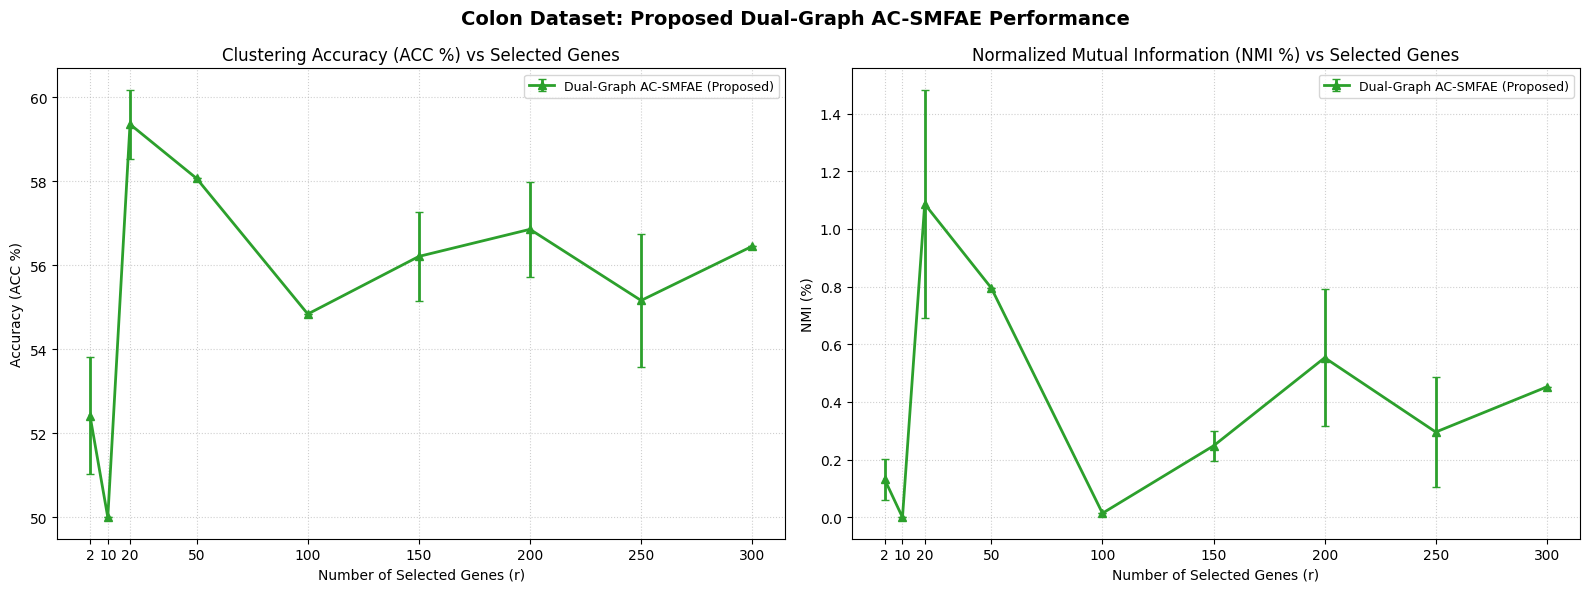

Graph saved to: d:\Projects\SMFS-AutoEncoder\reports\figures\Colon_All_Combinations_Comparison.png

CSV updated: d:\Projects\SMFS-AutoEncoder\reports\results\accuracy_nmi.csv
Colon feature subsets exported: 9
Total rows across all datasets: 83


,Dataset,Num_Selected_Features,ACC_Mean,ACC_STD,NMI_Mean,NMI_STD
0,Colon,2,52.419355,1.396815e+00,0.131304,6.953734e-02
1,Colon,10,50.000000,0.000000e+00,0.000000,0.000000e+00
2,Colon,20,59.354839,8.224225e-01,1.086239,3.962601e-01
3,Colon,50,58.064516,7.105427e-15,0.794804,0.000000e+00
4,Colon,100,54.838710,0.000000e+00,0.014272,1.734723e-18
5,Colon,150,56.209677,1.054572e+00,0.248011,5.279000e-02
6,Colon,200,56.854839,1.126148e+00,0.553309,2.375832e-01
7,Colon,250,55.161290,1.580316e+00,0.295704,1.917963e-01
8,Colon,300,56.451613,0.000000e+00,0.452305,5.551115e-17


In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create output directories
# ------------------------------------------------------------

figures_dir = "../reports/figures"
results_dir = "../reports/results"

os.makedirs(figures_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. Read evaluation results dynamically
# ------------------------------------------------------------

if "results_dual_ac_smfae_colon" not in globals():
    raise NameError(
        "Run Cell 2 first. results_dual_ac_smfae_colon was not found."
    )

results = results_dual_ac_smfae_colon
active_r_subsets = sorted(results.keys())

acc_means = [results[r]["ACC_mean"] for r in active_r_subsets]
acc_stds = [results[r]["ACC_std"] for r in active_r_subsets]
nmi_means = [results[r]["NMI_mean"] for r in active_r_subsets]
nmi_stds = [results[r]["NMI_std"] for r in active_r_subsets]

# ------------------------------------------------------------
# 3. Generate and save ACC/NMI comparison graph
# ------------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.errorbar(
    active_r_subsets, acc_means, yerr=acc_stds,
    label="Dual-Graph AC-SMFAE (Proposed)",
    color="#2ca02c", marker="^", linestyle="-",
    linewidth=2, capsize=3
)
ax1.set_title("Clustering Accuracy (ACC %) vs Selected Genes")
ax1.set_xlabel("Number of Selected Genes (r)")
ax1.set_ylabel("Accuracy (ACC %)")
ax1.set_xticks(active_r_subsets)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=9)

ax2.errorbar(
    active_r_subsets, nmi_means, yerr=nmi_stds,
    label="Dual-Graph AC-SMFAE (Proposed)",
    color="#2ca02c", marker="^", linestyle="-",
    linewidth=2, capsize=3
)
ax2.set_title("Normalized Mutual Information (NMI %) vs Selected Genes")
ax2.set_xlabel("Number of Selected Genes (r)")
ax2.set_ylabel("NMI (%)")
ax2.set_xticks(active_r_subsets)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(fontsize=9)

fig.suptitle(
    "Colon Dataset: Proposed Dual-Graph AC-SMFAE Performance",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()

fig_path = os.path.join(
    figures_dir, "Colon_All_Combinations_Comparison.png"
)
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Graph saved to: {os.path.abspath(fig_path)}")

# ------------------------------------------------------------
# 4. Build CSV rows dynamically from the result dictionary
# ------------------------------------------------------------

cfg = {
    "Alpha": 1e-2,
    "Beta": 1e-4,
    "Gamma": 1e-3,
    "Omega": 0.01,
    "Lam": 1e-4,
    "Eta": 1e-2
}

new_colon_rows = []

for r in active_r_subsets:
    res = results[r]

    new_colon_rows.append({
        "Method": "Dual-Graph AC-SMFAE (Proposed)",
        "Dataset": "Colon",
        "Num_Features": r,
        "ACC": res["ACC_mean"],
        "NMI": res["NMI_mean"],
        "Num_Samples": X.shape[1],
        "Num_Original_Features": X.shape[0],
        "Num_Classes": len(set(y)),
        "Num_Selected_Features": r,
        "Hidden_Dimension": W1_colon.shape[0],
        "Alpha": cfg["Alpha"],
        "Beta": cfg["Beta"],
        "Gamma": cfg["Gamma"],
        "Omega": cfg["Omega"],
        "Lam": cfg["Lam"],
        "Eta": cfg["Eta"],
        "ACC_Mean": res["ACC_mean"],
        "ACC_STD": res["ACC_std"],
        "NMI_Mean": res["NMI_mean"],
        "NMI_STD": res["NMI_std"],
        "Learning_Rate": 5e-4,
        "Epochs": 500,
        "KNN": 5,
        "Repetitions": 20
    })

df_colon_dynamic = pd.DataFrame(new_colon_rows)

# ------------------------------------------------------------
# 5. Update central CSV while preserving other datasets
# ------------------------------------------------------------

csv_file_path = os.path.join(results_dir, "accuracy_nmi.csv")

if os.path.exists(csv_file_path):
    existing_df = pd.read_csv(csv_file_path)

    if "Dataset" not in existing_df.columns:
        raise ValueError(
            "Existing CSV has no 'Dataset' column. "
            "Check its column names before updating it."
        )

    # Remove old Colon entries only; preserve ORL and Leukemia.
    preserved_df = existing_df[
        existing_df["Dataset"].astype(str).str.strip().str.upper()
        != "COLON"
    ]

    # Align columns so existing CSV structure is preserved,
    # while allowing new metadata columns if needed.
    all_columns = list(preserved_df.columns)

    for col in df_colon_dynamic.columns:
        if col not in all_columns:
            all_columns.append(col)

    combined_df = pd.concat(
        [
            preserved_df.reindex(columns=all_columns),
            df_colon_dynamic.reindex(columns=all_columns)
        ],
        ignore_index=True
    )
else:
    combined_df = df_colon_dynamic

combined_df.to_csv(csv_file_path, index=False)

print(f"\nCSV updated: {os.path.abspath(csv_file_path)}")
print(f"Colon feature subsets exported: {len(df_colon_dynamic)}")
print(f"Total rows across all datasets: {len(combined_df)}")

display(
    df_colon_dynamic[
        ["Dataset", "Num_Selected_Features",
         "ACC_Mean", "ACC_STD", "NMI_Mean", "NMI_STD"]
    ]
)